In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the dataset
df = pd.read_csv("iris.csv")

# Display the first 5 rows
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

Dataset loaded successfully!
Shape of dataset: (150, 5)


In [4]:
df.columns

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')

In [5]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [6]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 150
Columns: 5


In [7]:
# Check missing values in each column
print(df.isnull().sum())

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [8]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1


In [9]:
df.dtypes

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

In [10]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (149, 5)


In [11]:
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64

In [12]:
df[['sepal_length', 'sepal_width',
    'petal_length', 'petal_width']].mean()

sepal_length    5.843624
sepal_width     3.059732
petal_length    3.748993
petal_width     1.194631
dtype: float64

In [13]:
print("Maximum values:")
print(df.max(numeric_only=True))

print("\nMinimum values:")
print(df.min(numeric_only=True))

Maximum values:
sepal_length    7.9
sepal_width     4.4
petal_length    6.9
petal_width     2.5
dtype: float64

Minimum values:
sepal_length    4.3
sepal_width     2.0
petal_length    1.0
petal_width     0.1
dtype: float64


In [14]:
print("Average Petal Length:", np.mean(df['petal_length']))

Average Petal Length: 3.7489932885906043


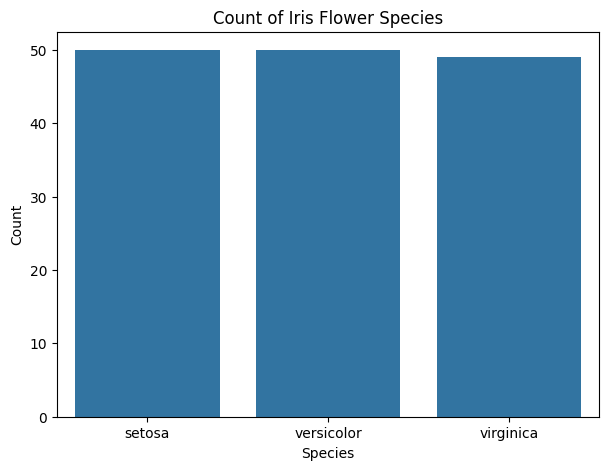

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='species')

plt.title("Count of Iris Flower Species")
plt.xlabel("Species")
plt.ylabel("Count")

plt.show()

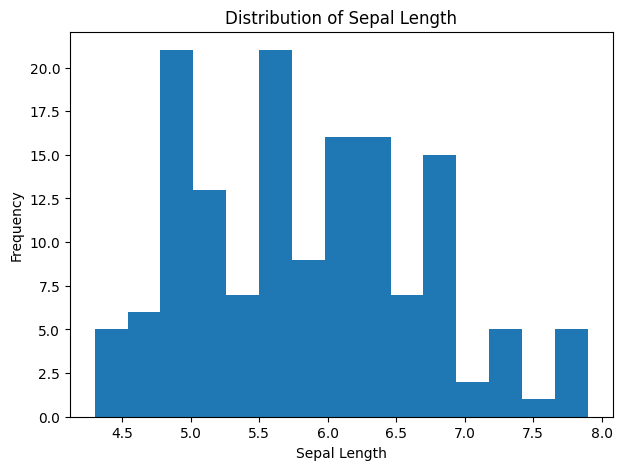

In [16]:
plt.figure(figsize=(7, 5))

plt.hist(df['sepal_length'], bins=15)

plt.title("Distribution of Sepal Length")
plt.xlabel("Sepal Length")
plt.ylabel("Frequency")

plt.show()

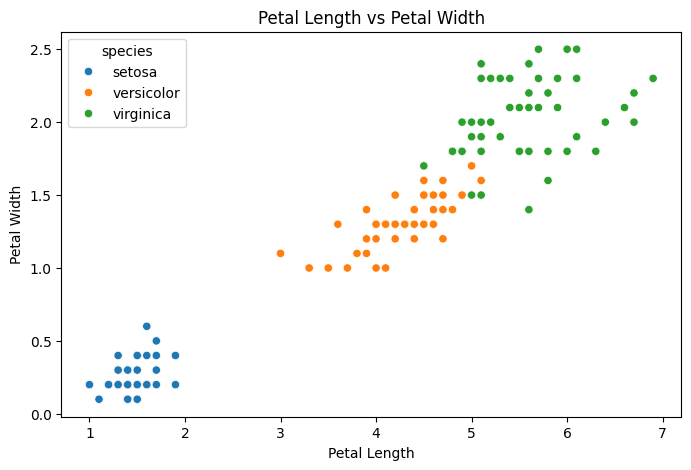

In [17]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='petal_length',
    y='petal_width',
    hue='species'
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

plt.show()

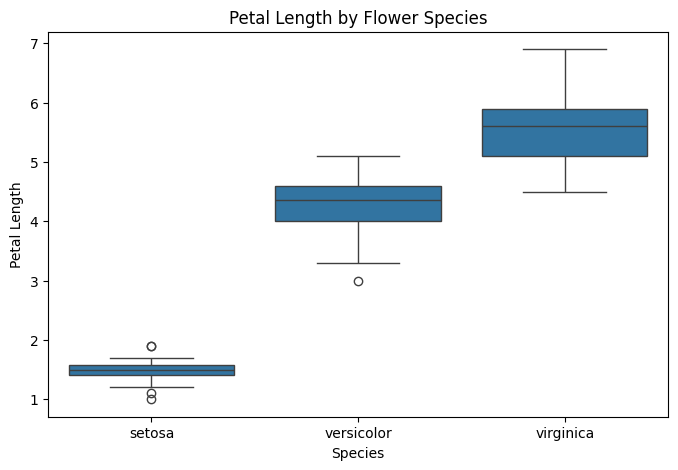

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='species', y='petal_length')

plt.title("Petal Length by Flower Species")
plt.xlabel("Species")
plt.ylabel("Petal Length")

plt.show()

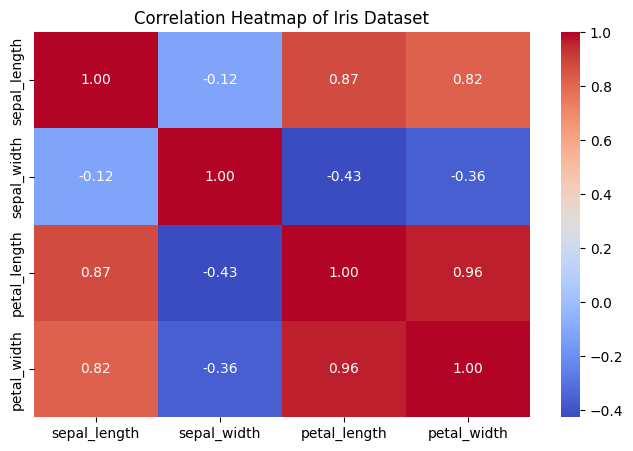

In [19]:
plt.figure(figsize=(8, 5))

correlation = df.select_dtypes(include='number').corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Heatmap of Iris Dataset")

plt.show()

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [21]:
X = df.drop('species', axis=1)
y = df['species']

print("Features and target separated successfully!")

Features and target separated successfully!


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data size:", X_train.shape)
print("Testing data size:", X_test.shape)

Training data size: (119, 4)
Testing data size: (30, 4)


In [23]:
model = RandomForestClassifier(random_state=42)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [24]:
y_pred = model.predict(X_test)

print("Predictions:", y_pred)

Predictions: ['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa'
 'versicolor' 'virginica' 'versicolor' 'versicolor' 'virginica' 'setosa'
 'setosa' 'setosa' 'setosa' 'versicolor' 'virginica' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'setosa' 'virginica'
 'virginica' 'virginica' 'virginica' 'virginica' 'setosa' 'setosa']


In [25]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 100.0 %


In [26]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



### Key Observations

1. The Iris dataset contains three flower species: Setosa, Versicolor, and Virginica.
2. One duplicate record was identified and removed.
3. No missing values were found in the dataset.
4. Petal length and petal width help distinguish different flower species.
5. The Random Forest model achieved 100% accuracy on the test dataset.
6. All 30 test samples were classified correctly.

### Conclusion

This project helped analyse the Iris dataset using Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn. Data visualization helped identify differences between flower species, while Scikit-learn was used to build a classification model that achieved 100% test accuracy.

In [27]:
print("Final Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Model Accuracy:", accuracy * 100, "%")

Final Dataset Shape: (149, 5)
Missing Values: 0
Duplicate Rows: 0
Model Accuracy: 100.0 %
